In [1]:
from langgraph.graph import StateGraph, START, END
from langchain_google_genai import ChatGoogleGenerativeAI
from typing import TypedDict
from dotenv import load_dotenv

In [2]:
load_dotenv()  # Load environment variables from .env file

True

In [3]:
model = ChatGoogleGenerativeAI(
    model = "gemini-3.5-flash-lite",
    temperature = 0

)


In [4]:
class BlogState(TypedDict):

    title: str
    outline: str
    content: str

In [5]:
def create_outline(state: BlogState) -> BlogState:

    # fetch title
    title = state['title']

    # call llm gen outline
    prompt = f'Generate a detailed outline for a blog on the topic - {title}'
    outline = model.invoke(prompt).content

    # update state
    state['outline'] = outline

    return state

In [6]:
def create_blog(state: BlogState) -> BlogState:

    title = state['title']
    outline = state['outline']

    prompt = f'Write a detailed blog on the title - {title} using the follwing outline \n {outline}'

    content = model.invoke(prompt).content

    state['content'] = content

    return state

In [7]:
graph = StateGraph(BlogState)

# nodes
graph.add_node('create_outline', create_outline)
graph.add_node('create_blog', create_blog)

# edges
graph.add_edge(START, 'create_outline')
graph.add_edge('create_outline', 'create_blog')
graph.add_edge('create_blog', END)

workflow = graph.compile()

In [8]:
intial_state = {'title': 'Rise of AI in India'}

final_state = workflow.invoke(intial_state)

print(final_state)

d:\VS code\Python\Langgraph\venv\Lib\site-packages\langchain_google_genai\chat_models.py:3940: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
d:\VS code\Python\Langgraph\venv\Lib\site-packages\langchain_google_genai\chat_models.py:3940: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


{'title': 'Rise of AI in India', 'outline': [{'type': 'text', 'text': 'Here is a comprehensive and detailed blog outline on the topic **"The Rise of AI in India: Transforming the Nation’s Future."** \n\nThis outline is structured to be engaging, SEO-friendly, and informative for a broad audience, ranging from tech enthusiasts to business professionals.\n\n---\n\n# Blog Title Options:\n*   *Namaste AI: How India is Becoming a Global Artificial Intelligence Powerhouse*\n*   *From IT Backoffice to AI Innovation Hub: The Rise of AI in India*\n*   *The AI Revolution in India: Opportunities, Challenges, and the Road Ahead*\n\n---\n\n## I. Introduction\n*   **The Hook:** Start with a relatable scenario—how Indians interact with AI daily (e.g., asking a voice assistant in Hindi, using UPI apps with AI fraud detection, or browsing through AI-curated e-commerce feeds).\n*   **The Shift:** Briefly explain India\'s transition from being just a back-office IT service provider to a front-runner in c

In [9]:
print(final_state['outline'])

[{'type': 'text', 'text': 'Here is a comprehensive and detailed blog outline on the topic **"The Rise of AI in India: Transforming the Nation’s Future."** \n\nThis outline is structured to be engaging, SEO-friendly, and informative for a broad audience, ranging from tech enthusiasts to business professionals.\n\n---\n\n# Blog Title Options:\n*   *Namaste AI: How India is Becoming a Global Artificial Intelligence Powerhouse*\n*   *From IT Backoffice to AI Innovation Hub: The Rise of AI in India*\n*   *The AI Revolution in India: Opportunities, Challenges, and the Road Ahead*\n\n---\n\n## I. Introduction\n*   **The Hook:** Start with a relatable scenario—how Indians interact with AI daily (e.g., asking a voice assistant in Hindi, using UPI apps with AI fraud detection, or browsing through AI-curated e-commerce feeds).\n*   **The Shift:** Briefly explain India\'s transition from being just a back-office IT service provider to a front-runner in creating native AI solutions.\n*   **Thesis S

In [10]:
print(final_state['content'])

[{'type': 'text', 'text': '# From IT Backoffice to AI Innovation Hub: The Rise of AI in India\n\nPicture this: It’s a bustling Tuesday morning in a tier-2 city like Indore or Jaipur. You step out, book an auto-rickshaw using a voice assistant in fluent Hindi, scan a QR code to pay via a UPI app equipped with real-time AI fraud detection, and later, browse through an e-commerce app that suggests handloom products curated precisely to your regional tastes. \n\nArtificial Intelligence is no longer a futuristic, sci-fi concept confined to research labs in Silicon Valley. It is woven into the very fabric of daily life in India. \n\nFor decades, India was globally recognized as the back-office of the world—the go-to destination for IT outsourcing, maintenance, and software services. But the script has flipped. Driven by a massive talent pool, digital public infrastructure, and robust government backing, India is experiencing an unprecedented AI boom. Today, the nation is not just consuming A

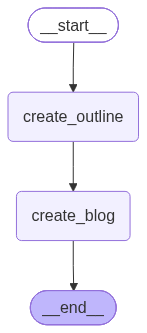

In [11]:
from IPython.display import Image, display
Image(workflow.get_graph().draw_mermaid_png())

now tell me in intial state we are sending the topic name then where we define the topic and how it took input